# **Data loading and initial inspection**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

### **Loding the Dataset**

In [ ]:
df = pd.read_csv('online_retail_II.csv')

### **Inspecting the last and first records**

In [ ]:
df.head()
df.tail()
df.sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
37601,492445,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,24,2009-12-17 11:07:00,3.39,17230.0,United Kingdom
103569,499275,21181,PLEASE ONE PERSON METAL SIGN,6,2010-02-25 17:37:00,2.10,13652.0,United Kingdom
41266,492784,84327A,PINK JUMPER LARRY THE LAMB,1,2009-12-18 17:24:00,2.10,17841.0,United Kingdom
17327,490753,21080,SET/20 RED SPOTTY PAPER NAPKINS,12,2009-12-08 08:48:00,0.85,17047.0,United Kingdom
87632,497591,20748,KENSINGTON COFFEE SET,1,2010-02-10 18:02:00,8.47,NaN,United Kingdom
60412,494786,22358,KINGS CHOICE TEA CADDY,1,2010-01-18 13:24:00,5.91,NaN,United Kingdom
77231,496431,22276,WASH BAG VINTAGE ROSE PAISLEY,1,2010-02-01 12:30:00,2.55,16415.0,United Kingdom
100722,498905,21908,CHOCOLATE THIS WAY METAL SIGN,3,2010-02-23 14:40:00,2.10,12854.0,United Kingdom
34947,492303,84609,TALL ROCOCO CANDLE HOLDER,1,2009-12-16 11:57:00,17.35,NaN,United Kingdom
34592,492302,21992,VINTAGE PAISLEY STATIONERY SET,6,2009-12-16 11:56:00,2.95,16119.0,United Kingdom


### **Understanding Dataset Dimension and structure**

In [ ]:
df.shape #rows & columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106206 entries, 0 to 106205
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      106206 non-null  object 
 1   StockCode    106206 non-null  object 
 2   Description  105246 non-null  object 
 3   Quantity     106206 non-null  int64  
 4   InvoiceDate  106206 non-null  object 
 5   Price        106205 non-null  float64
 6   Customer ID  78139 non-null   float64
 7   Country      106205 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 6.5+ MB


### **Data type & their unique values**

In [ ]:
df.dtypes
df.nunique() #checking unique values


,0
Invoice,5935
StockCode,3803
Description,3451
Quantity,399
InvoiceDate,5139
Price,594
Customer ID,1803
Country,28


### **Inspecting individual columns** (help to see all unique values)

In [ ]:
df['Country'].unique()
df['Invoice'].unique()
df['StockCode'].unique()
df['InvoiceDate'].unique()

<DatetimeArray>
['2009-12-01 07:45:00', '2009-12-01 07:46:00', '2009-12-01 09:06:00',
 '2009-12-01 09:08:00', '2009-12-01 09:24:00', '2009-12-01 09:28:00',
 '2009-12-01 09:43:00', '2009-12-01 09:44:00', '2009-12-01 09:46:00',
 '2009-12-01 09:50:00',
 ...
 '2010-02-28 15:21:00', '2010-02-28 15:58:00', '2010-02-28 16:00:00',
 '2010-02-28 16:01:00', '2010-02-28 16:14:00', '2010-02-28 16:16:00',
 '2010-03-01 08:38:00', '2010-03-01 08:55:00', '2010-03-01 09:13:00',
                 'NaT']
Length: 5139, dtype: datetime64[ns]

### **Datatype Correction of incorrect data**

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce') #vonvert to standard datetime format
df['Customer ID'] = df['Customer ID'].astype('string') #it convert the the customer column in string datatype
df['Invoice'] = df['Invoice'].astype('string')
df['StockCode'] = df['StockCode'].astype('string')


In [ ]:
#Checking Date range
df['InvoiceDate'].min()
df['InvoiceDate'].max()

Timestamp('2010-03-01 09:13:00')

### **Questions**
Is the dataset covering a continuous period?



Are all dates valid?



Are invoice and customer identifiers being treated correctly?



Are there unusual stock codes?

#  **Data Cleaning & all**

In [ ]:
#Calculating Missing Values
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,960
Quantity,0
InvoiceDate,1
Price,1
Customer ID,28067
Country,1


In [ ]:
#---Missing Percentage---
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_percentage.sort_values(ascending=False)

,0
Customer ID,26.426944
Description,0.903904
InvoiceDate,0.000942
Price,0.000942
Country,0.000942
Quantity,0.000000
Invoice,0.000000
StockCode,0.000000


### visualize missing values

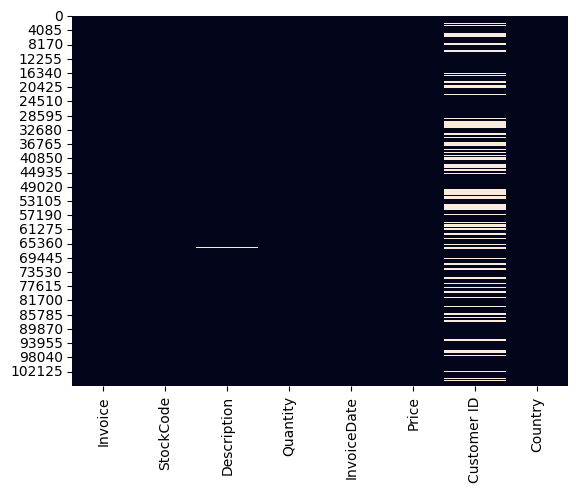

In [ ]:
sns.heatmap(df.isnull(), cbar=False)
plt.show()

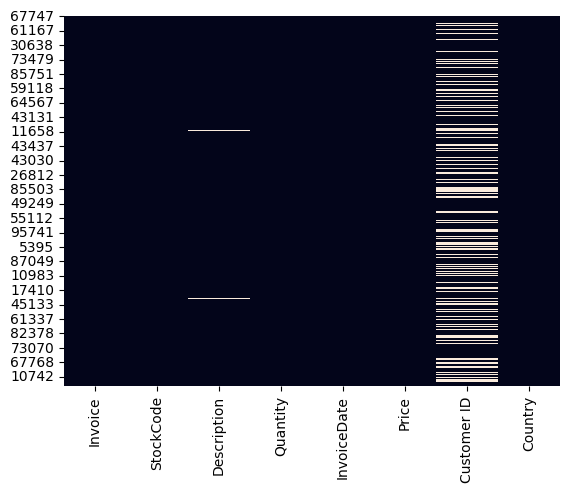

In [ ]:
sns.heatmap(
    df.sample(1000).isnull(),
    cbar=False
)
plt.show()

### Questions on missing Customer IDs
* Which countries have the highest number of unidentified customers?



* Are unidentified customers associated with particular products?



* Are missing IDs concentrated in certain months?



* Do unidentified transactions have unusual quantities or prices?


### **Q1: Which countries have the highest number of unidentified customers?**

In [ ]:
# Create a flag for missing Customer ID
country_missing = (
    df['Customer ID'].isna()
    .groupby(df['Country'])
    .agg(Total_Transactions='count', Missing_Customer_IDs='sum')
    .assign(Missing_Percentage=lambda x: (x['Missing_Customer_IDs'] / x['Total_Transactions']) * 100)
    .sort_values('Missing_Customer_IDs', ascending=False)
)

display(country_missing.head(10))


,Total_Transactions,Missing_Customer_IDs,Missing_Percentage
Country,,,
United Kingdom,99288,27839,28.038635
EIRE,1698,109,6.419317
United Arab Emirates,198,87,43.939394
Bahrain,29,29,100.000000
Nigeria,3,2,66.666667
Belgium,178,0,0.000000
Cyprus,249,0,0.000000
Denmark,83,0,0.000000
Finland,39,0,0.000000


### **Q2: Are unidentified customers associated with particular products?**

In [ ]:
# Filter for missing customer IDs and check the most frequent product descriptions
missing_cust_df = df[df['is_missing_cust']]
top_missing_products = missing_cust_df['Description'].value_counts().head(15).reset_index()
top_missing_products.columns = ['Description', 'Missing_ID_Transaction_Count']

display(top_missing_products)

,Description,Missing_ID_Transaction_Count
0,DOTCOM POSTAGE,146
1,PACK OF 72 RETRO SPOT CAKE CASES,82
2,STRAWBERRY CERAMIC TRINKET BOX,75
3,WHITE HANGING HEART T-LIGHT HOLDER,73
4,SCOTTIE DOG HOT WATER BOTTLE,67
5,PINK HEART DOTS HOT WATER BOTTLE,64
6,PAPER CHAIN KIT 50'S CHRISTMAS,62
7,HOT WATER BOTTLE TEA AND SYMPATHY,62
8,PACK OF 60 PINK PAISLEY CAKE CASES,60
9,"METAL SIGN,CUPCAKE SINGLE HOOK",59


### **Q3: Are missing IDs concentrated in certain months?**

In [ ]:
# Extract Year-Month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Group by month and calculate the percentage of missing customer IDs
monthly_missing = df.groupby('YearMonth')['is_missing_cust'].agg(['count', 'sum']).rename(columns={'count': 'Total_Transactions', 'sum': 'Missing_Customer_IDs'})
monthly_missing['Missing_Percentage'] = (monthly_missing['Missing_Customer_IDs'] / monthly_missing['Total_Transactions']) * 100

display(monthly_missing)

,Total_Transactions,Missing_Customer_IDs,Missing_Percentage
YearMonth,,,
2009-12,45228,13468,29.778014
2010-01,31555,9116,28.889241
2010-02,29388,5482,18.653872
2010-03,34,0,0.000000


### **Q4: Do unidentified transactions have unusual quantities or prices?**

In [ ]:
# Compare descriptive statistics of Quantity and Price between identified and unidentified customers
comparison = df.groupby('is_missing_cust')[['Quantity', 'Price']].describe()
display(comparison.transpose())

is_missing_cust         False         True 
Quantity count   78139.000000  28067.000000
         mean       14.385352      1.429401
         std       125.050360     61.379526
         min     -2504.000000  -4200.000000
         25%         2.000000      1.000000
         50%         4.000000      1.000000
         75%        12.000000      2.000000
         max     19152.000000   4200.000000
Price    count   78139.000000  28066.000000
         mean        3.756010      6.676308
         std        49.218829     43.595473
         min         0.000000      0.000000
         25%         1.250000      1.700000
         50%         2.100000      3.430000
         75%         3.750000      6.040000
         max      8985.600000   5117.030000

In [ ]:
#Missing Description
df[df['Description'].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_missing_cust,YearMonth
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,True,2009-12
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,True,2009-12
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,<NA>,United Kingdom,True,2009-12
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,<NA>,United Kingdom,True,2009-12
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom,True,2009-12
...,...,...,...,...,...,...,...,...,...,...
104664,499416,21298,NaN,-15,2010-02-26 16:15:00,0.0,<NA>,United Kingdom,True,2010-02
104665,499415,21299,NaN,-8,2010-02-26 16:15:00,0.0,<NA>,United Kingdom,True,2010-02
104666,499417,82585,NaN,-90,2010-02-26 16:16:00,0.0,<NA>,United Kingdom,True,2010-02
104667,499418,21697,NaN,-499,2010-02-26 16:19:00,0.0,<NA>,United Kingdom,True,2010-02
